# Tree Data Extraction and Analysis

This notebook demonstrates how to load, inspect, and extract tree positions and heights from the local GeoPackage (`.gpkg`) tree database (`Trees/125015_baeume.gpkg`).

In [1]:
import os
import pandas as pd
import geopandas as gpd
import contextily as cx
import matplotlib.pyplot as plt
from shapely.geometry import box
from pyproj import Transformer


### 2. Path

In [2]:
TREE_GPKG_PATH = '../Trees/125015_baeume.gpkg'


### 3. Load the Tree Dataset

In [3]:
query_box = box(561000, 5505000, 575000, 5523000)
print("Loading tree dataset")
trees_gdf = gpd.read_file(TREE_GPKG_PATH, bbox=query_box)
print(f"Loaded {len(trees_gdf):,} trees.")
print("CRS of the dataset:", trees_gdf.crs)
trees_gdf.head()

Loading tree dataset
Loaded 928,531 trees.
CRS of the dataset: EPSG:25832


,dgmhoehe,baumhoehe,geometry
0,339.6,34.4,POINT (562018.5 5507559.1)
1,340.1,29.0,POINT (562009.9 5507560.7)
2,339.1,27.1,POINT (562025.3 5507562.7)
3,339.6,28.0,POINT (562011.7 5507567.5)
4,336.8,27.0,POINT (562049.5 5507568.5)


In [5]:
cone_height_ratio = 0.6
cone_radius_ratio = 0.4

trees_gdf["cone_height"] = trees_gdf["baumhoehe"] * cone_height_ratio

trees_gdf["trunk_height"] = trees_gdf["baumhoehe"] - trees_gdf["cone_height"]

trees_gdf["cone_radius"] = trees_gdf["cone_height"] * cone_radius_ratio

display(trees_gdf[["geometry", "baumhoehe", "dgmhoehe", "trunk_height", "cone_height", "cone_radius"]].head())

,geometry,baumhoehe,dgmhoehe,trunk_height,cone_height,cone_radius
0,POINT (562018.5 5507559.1),34.4,339.6,13.76,20.64,8.256
1,POINT (562009.9 5507560.7),29.0,340.1,11.60,17.40,6.960
2,POINT (562025.3 5507562.7),27.1,339.1,10.84,16.26,6.504
3,POINT (562011.7 5507567.5),28.0,339.6,11.20,16.80,6.720
4,POINT (562049.5 5507568.5),27.0,336.8,10.80,16.20,6.480


### Spatially Filter Trees for the Study Area

In [6]:
from shapely.geometry import box

# Define the GeoData study area bounding box
query_box = box(561000, 5505000, 575000, 5523000)

# Spatially filter trees within the study area box
trees_filtered = trees_gdf[trees_gdf.geometry.intersects(query_box)].copy()
print(f"Filtered {len(trees_filtered):,} trees inside the study area.")

Filtered 928,531 trees inside the study area.


C:\Users\DELL\AppData\Local\Programs\Python\Python313\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


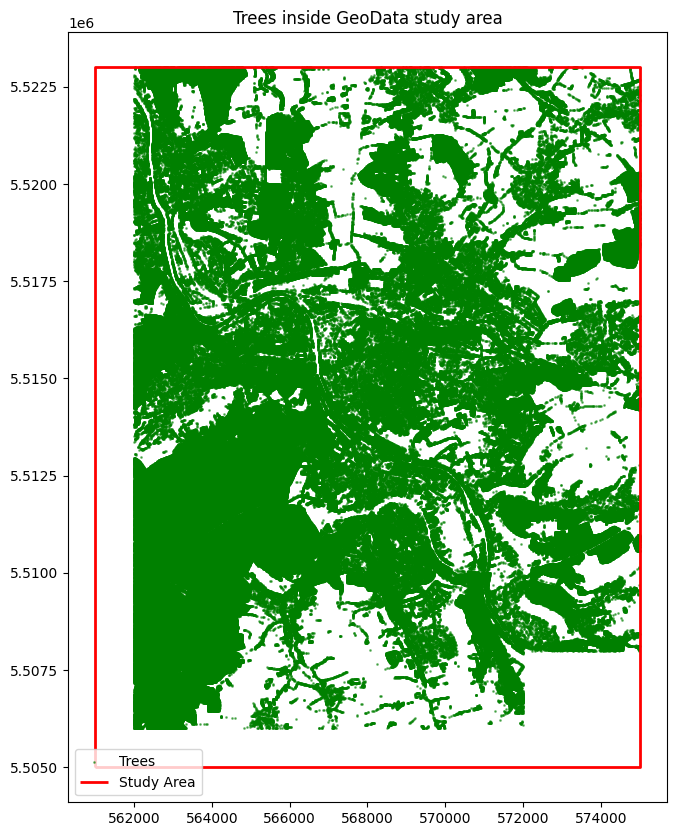

In [7]:
fig, ax = plt.subplots(figsize=(10, 10))
trees_filtered.plot(ax=ax, color='green', markersize=1, alpha=0.5, label='Trees')
gpd.GeoSeries([query_box], crs=trees_filtered.crs).boundary.plot(ax=ax, color='red', linewidth=2, label='Study Area')
ax.set_title("Trees inside GeoData study area")
plt.legend()
plt.show()

### 4. Extract Tree Features

In [8]:
trees_filtered['Tree_Position_X'] = trees_filtered.geometry.x
trees_filtered['Tree_Position_Y'] = trees_filtered.geometry.y

columns_to_keep = ['Tree_Position_X', 'Tree_Position_Y', 'baumhoehe', 'dgmhoehe', 'cone_height', 'cone_radius']
trees_filtered = trees_filtered[columns_to_keep]
trees_filtered.head()

,Tree_Position_X,Tree_Position_Y,baumhoehe,dgmhoehe,cone_height,cone_radius
0,562018.5,5507559.1,34.4,339.6,20.64,8.256
1,562009.9,5507560.7,29.0,340.1,17.40,6.960
2,562025.3,5507562.7,27.1,339.1,16.26,6.504
3,562011.7,5507567.5,28.0,339.6,16.80,6.720
4,562049.5,5507568.5,27.0,336.8,16.20,6.480


### 5. Inspect Tree Heights and Statistics

In [9]:
print("Tree Height (baumhoehe) statistics (meters):")
print(trees_filtered['baumhoehe'].describe())

print("\nGround Elevation (dgmhoehe) statistics (meters):")
print(trees_filtered['dgmhoehe'].describe())

Tree Height (baumhoehe) statistics (meters):
count    928531.000000
mean         18.866040
std           8.473649
min           5.500000
25%          11.100000
50%          19.100000
75%          25.700000
max          48.700000
Name: baumhoehe, dtype: float64

Ground Elevation (dgmhoehe) statistics (meters):
count    928531.000000
mean        274.242347
std          47.731753
min         164.800000
25%         244.000000
50%         276.400000
75%         308.600000
max         374.900000
Name: dgmhoehe, dtype: float64


### 6. Output

In [10]:
import os
import json
out_dir = r"E:\EnergyPraktikum_main\outputs"

trees_filtered.to_csv(os.path.join(out_dir, "wuerzburg_extracted_trees.csv"), index=False)

trees_filtered_dict = trees_filtered.to_dict(orient="records")
with open(os.path.join(out_dir, "wuerzburg_extracted_trees.json"), "w", encoding="utf-8") as f:
    json.dump(trees_filtered_dict, f)
